# Reteniendo un muestreo: lo que el modelo calibrado predice para una planta que no ha visto

**Pregunta:** Cuando el modelo de capacidad calibrado se reajusta sin un muestreo, ¿qué tan bien predice el tonelaje de ese muestreo, y cuánto mejor es eso que adivinar la media de los otros?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 y 02 del tema 05-real-surveys
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook usted puede:

- explicar qué es un pliegue de dejar un muestreo afuera, y decir qué filas ajusta y cuál predice;
- reajustar el modelo de capacidad calibrado con nueve muestreos y leer su predicción retenida para el décimo;
- comparar las diez predicciones retenidas con la línea base de media constante que daría un modelo sin habilidad;
- decir por qué existe la variante con fuga del pliegue, y dónde se hace su comparación completa.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el motor con su vía calibrada y el módulo CrusherCal del pipeline, cuyas funciones públicas ajustan y predicen pliegue por pliegue. Cada importación del pipeline lleva su comentario.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# el lector que valida la tabla de muestreos
from pipeline.hp500.surveys import read_surveys
# el motor y el punto de operación de la vía calibrada
from pipeline.model.crusher import evaluate, operating_from_survey
# la base de capacidad del artículo
from pipeline.model.crusher.capacity import HP500_QREF
# CrusherCal: los pliegues, los ajustes y las métricas
from pipeline.hp500 import loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivo leído: `data/examples/hp500-surveys.csv`. Los resultados del motor en los muestreos se calculan en el notebook, y no se lee de vuelta nada versionado.

La celda lee la tabla y deja el tonelaje medido y los dos regresores del modelo libre, la abertura y el f80 de alimentación.

In [2]:
# Lea la tabla de muestreos y deje el tonelaje medido y los regresores, la abertura y el f80
surveys = read_surveys().accepted
measured = np.array([s.feed_tph for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
print("muestreos:", len(surveys), "| tonelaje medido [t/h]:", measured)

muestreos: 10 | tonelaje medido [t/h]: [1639. 1267. 1240. 1034. 1124.  813. 1050. 1138.  820. 1334.]


## Método

**Paso 1, el pliegue.** Un modelo que se ajusta a diez muestreos y se juzga con los mismos diez dice qué tan bien los describe, no cómo le iría con un undécimo. El protocolo de dejar un muestreo afuera responde la segunda pregunta: para cada muestreo $i$, se ajusta con los otros nueve y se predice $i$, y luego se juzgan juntas las diez predicciones. El único número libre del modelo para el tonelaje es la base de capacidad $Q_T$, que cada pliegue reajusta con sus nueve muestreos por mínimos cuadrados (Rocha et al., 2024; https://doi.org/10.3390/min14090919). CrusherCal construye los pliegues con `loo.fold_indices`, y la celda imprime las filas de entrenamiento del muestreo 3 en el pliegue estricto y en la variante con fuga, que deja al muestreo dentro de su propio conjunto de entrenamiento y existe para medir cuánto eso favorece a un modelo.

In [3]:
# Filas de entrenamiento del muestreo 3 (índice 2) en el pliegue estricto y en la variante con fuga
print("pliegue estricto, filas ajustadas:", loo.fold_indices(10, 2, leaky=False).tolist())
print("variante con fuga, filas ajustadas:", loo.fold_indices(10, 2, leaky=True).tolist())

pliegue estricto, filas ajustadas: [0, 1, 3, 4, 5, 6, 7, 8, 9]
variante con fuga, filas ajustadas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Las dos predicciones del muestreo 3 se hacen con las funciones públicas de CrusherCal, que `loo.build` llama pliegue por pliegue. El modelo de capacidad M0 predice la base de capacidad ajustada a las filas de entrenamiento (`fit_capacity_base`) por el factor de capacidad del muestreo (`predict_capacity`), donde el factor es el tonelaje del motor sobre la base de 647 t/h del artículo. La regresión libre M2 (`fit_freeform`, `predict_freeform`) ajusta un plano en la abertura y el f80 sin física alguna. La celda pide ambas en el pliegue estricto y en el de fuga, junto a la medición, e imprime los tres coeficientes de M2.

In [4]:
# Prediga el muestreo 3 con el modelo de capacidad (M0) y la regresión libre (M2), estricto y con fuga
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
shape = np.array([r.throughput_tph for r in runs]) / HP500_QREF
for name, leaky in (("estricto", False), ("con fuga", True)):
    rows = loo.fold_indices(10, 2, leaky=leaky)
    qt = loo.fit_capacity_base(shape, measured, rows)
    coef = loo.fit_freeform(features, measured, rows)
    m0 = loo.predict_capacity(qt, shape, 2)
    m2 = loo.predict_freeform(coef, features[2])
    print(f"{name:9s} QT {qt:6.1f}  M0 {m0:7.1f} t/h  M2 {m2:7.1f} t/h  medido {measured[2]:.0f} t/h")
    print("          coeficientes de M2 (intercepto, abertura, f80):", np.round(coef, 2))

estricto  QT  681.5  M0  1165.8 t/h  M2   981.0 t/h  medido 1240 t/h
          coeficientes de M2 (intercepto, abertura, f80): [-1100.32    38.94     4.51]
con fuga  QT  686.0  M0  1173.4 t/h  M2  1078.3 t/h  medido 1240 t/h
          coeficientes de M2 (intercepto, abertura, f80): [-802.3    36.56    2.68]


El pliegue con fuga, que ha visto el muestreo 3, queda más cerca de la medición que el estricto en ambos modelos, y la regresión libre es la que más gana con la fuga, pues tiene más coeficientes para doblarse hacia el punto que vio: sus tres coeficientes se mueven visiblemente entre los dos pliegues, mientras el modelo de capacidad mueve solo su única base. La base de capacidad es el número que cada pliegue reajusta, y la celda siguiente la imprime para los diez pliegues estrictos.

In [5]:
# La base de capacidad reajustada por cada uno de los diez pliegues estrictos
folds = [loo.fold_indices(10, i, leaky=False) for i in range(10)]
bases = [loo.fit_capacity_base(shape, measured, rows) for rows in folds]
print("base de capacidad reajustada por pliegue [t/h]:", np.round(bases, 1))
print("rango:", round(min(bases), 1), "a", round(max(bases), 1), "| valor del artículo:", HP500_QREF)

base de capacidad reajustada por pliegue [t/h]: [659.3 687.1 681.5 695.3 689.3 698.3 682.9 683.7 697.9 683.4]
rango: 659.3 a 698.3 | valor del artículo: 647


La base se mueve entre 659 y 698 t/h de un pliegue a otro, una dispersión de cerca de 6 por ciento producida por sacar un muestreo de diez, y todos los pliegues quedan sobre los 647 t/h del artículo: eso es lo que se mueve un ajuste de un parámetro con diez puntos, y la incertidumbre que arrastra un único valor dentro de la muestra y que el protocolo con retención hace visible.

**Paso 2, las predicciones retenidas.** Con los diez pliegues, la predicción retenida del muestreo $i$ es el factor de capacidad de $i$ por la base que ajustó su pliegue. La celda lista la predicción de cada muestreo junto a la medición, el residuo (el medido menos el predicho), el error como porcentaje de la medición, y el error porcentual absoluto medio de `loo.mape`. Un muestreo con residuo grande es uno para el que los otros nueve no prepararon al modelo.

In [6]:
# Predicción retenida del modelo de capacidad para cada muestreo, junto a la medición, y su MAPE
held_out = np.array([loo.predict_capacity(qt, shape, i) for i, qt in enumerate(bases)])
print("muestreo  medido  retenido   residuo     error")
for s, m, p in zip(surveys, measured, held_out):
    print(f"{s.survey:8d} {m:7.0f} {p:9.1f} {m - p:+9.1f} {(p - m) / m * 100:+7.1f} %")
print("MAPE retenido del modelo de capacidad:", round(loo.mape(measured, held_out), 2), "%")

muestreo  medido  retenido   residuo     error
       1    1639    1231.9    +407.1   -24.8 %
       2    1267    1283.8     -16.8    +1.3 %
       3    1240    1165.8     +74.2    -6.0 %
       4    1034    1189.4    -155.4   +15.0 %
       5    1124    1179.1     -55.1    +4.9 %
       6     813    1047.5    -234.5   +28.8 %
       7    1050     988.4     +61.6    -5.9 %
       8    1138    1097.5     +40.5    -3.6 %
       9     820    1046.9    -226.9   +27.7 %
      10    1334    1294.9     +39.1    -2.9 %
MAPE retenido del modelo de capacidad: 12.09 %


Los residuos son de ambos signos y de tamaños muy distintos: el muestreo 1 es el extremo, 407 t/h sobre lo que predicen los otros nueve, y los muestreos 6 y 9, con 40 mm y 813 y 820 t/h, quedan unos 230 t/h bajo. La figura pone las predicciones retenidas en un gráfico de paridad contra las mediciones, con la banda de 29 por ciento que usó el filtro de expectativas del notebook 02 del tema 05.

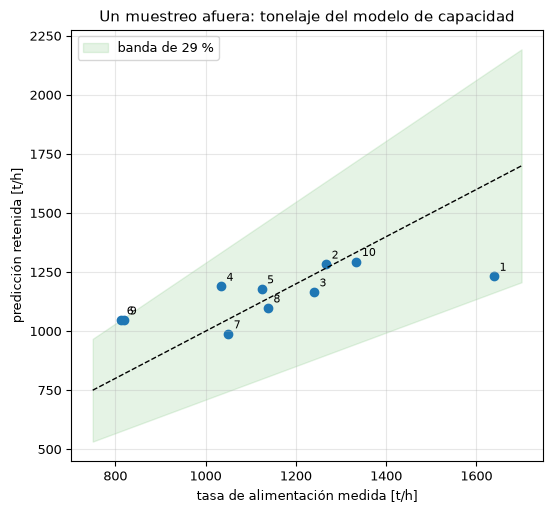

In [7]:
# Gráfico de paridad de las predicciones retenidas contra el tonelaje medido, con la banda de 29 %
fig, ax = plt.subplots(figsize=(5.6, 5.2))
line = np.array([750, 1700])
ax.fill_between(line, line * 0.71, line * 1.29, color="tab:green", alpha=0.12, label="banda de 29 %")
ax.plot(line, line, "k--", lw=1)
ax.scatter(measured, held_out)
for s, m, p in zip(surveys, measured, held_out):
    ax.annotate(str(s.survey), (m, p), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("tasa de alimentación medida [t/h]")
ax.set_ylabel("predicción retenida [t/h]")
ax.set_title("Un muestreo afuera: tonelaje del modelo de capacidad")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Los diez puntos caen dentro de la banda verde, y tres de ellos cerca de su borde: el muestreo 1 queda 24,8 por ciento bajo su medición (1232 frente a 1639 t/h), y los muestreos 6 y 9 quedan 28,8 y 27,7 por ciento sobre las suyas, como imprimió la columna de error. Las predicciones ocupan un rango angosto, de 988 a 1295 t/h, mucho más angosto que las mediciones, porque el modelo solo conoce la abertura. Lo que la figura no puede decir es si esto es bueno: un modelo que predijera siempre el mismo número también caería dentro de una banda ancha. La comparación con ese modelo es el paso siguiente.

**Paso 3, la línea base.** Un modelo sin habilidad predice, para el muestreo retenido, la media de los otros nueve: la línea base de media constante. Un modelo que valga algo debe superarla, con retención. La celda construye la línea base pliegue por pliegue, retiene la regresión libre M2 en los mismos diez pliegues, e imprime el error porcentual absoluto medio de los tres con `loo.mape`, y los muestreos en que el modelo de capacidad supera a la línea base. La figura dibuja el error absoluto de cada muestreo para el modelo de capacidad y para la línea base.

In [8]:
# La línea base de media constante y la regresión libre, ambas con retención, junto al modelo de capacidad
baseline = np.array([measured[rows].mean() for rows in folds])
free_form = np.array([loo.predict_freeform(loo.fit_freeform(features, measured, rows), features[i])
                      for i, rows in enumerate(folds)])
models = (("modelo de capacidad M0", held_out), ("regresión libre M2", free_form),
          ("media de los otros nueve", baseline))
for name, pred in models:
    print(f"{name:25s} MAPE retenido {loo.mape(measured, pred):6.2f} %")
better = np.abs(held_out - measured) < np.abs(baseline - measured)
print("muestreos en que el modelo supera la línea base:", int(better.sum()), "de 10:", np.flatnonzero(better) + 1)
print("predicción de la línea base para los muestreos 4, 5 y 8 [t/h]:", baseline[[3, 4, 7]].round(0))

modelo de capacidad M0    MAPE retenido  12.09 %
regresión libre M2        MAPE retenido  12.18 %
media de los otros nueve  MAPE retenido  18.29 %
muestreos en que el modelo supera la línea base: 7 de 10: [ 1  2  3  6  7  9 10]
predicción de la línea base para los muestreos 4, 5 y 8 [t/h]: [1158. 1148. 1147.]


La figura compara los dos errores absolutos muestreo por muestreo, en porcentaje de la medición.

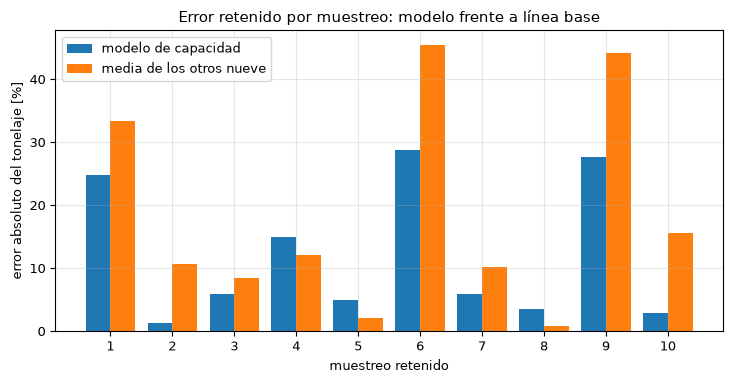

In [9]:
# Error absoluto retenido del modelo de capacidad y de la línea base, por muestreo
x = np.arange(1, 11)
fig, ax = plt.subplots()
ax.bar(x - 0.2, np.abs(held_out - measured) / measured * 100, 0.4, label="modelo de capacidad")
ax.bar(x + 0.2, np.abs(baseline - measured) / measured * 100, 0.4, label="media de los otros nueve")
ax.set_xticks(x)
ax.set_xlabel("muestreo retenido")
ax.set_ylabel("error absoluto del tonelaje [%]")
ax.set_title("Error retenido por muestreo: modelo frente a línea base")
ax.legend()
fig.tight_layout()
plt.show()

El modelo de capacidad supera a la línea base en 7 de los 10 muestreos (1, 2, 3, 6, 7, 9 y 10) y pierde en el 4, el 5 y el 8: las barras muestran que la línea base gana justo en los muestreos cuyo tonelaje (1034, 1124 y 1138 t/h) queda cerca de la media de los otros nueve, que imprimió la última línea, y que el modelo gana con claridad en los extremos que puede seguir mediante la abertura. En los totales el modelo está en 12,09 por ciento frente a 18,29 por ciento de la línea base, y la regresión libre, con sus tres coeficientes ajustados, está en 12,18 por ciento: con retención, no es mejor que la física. La figura muestra el orden; no muestra qué tan estable es con diez puntos, que es lo que examina el notebook 02, y la comparación de estos números retenidos con los números dentro de la muestra de los mismos modelos se hace una sola vez, en el notebook 03.

## Resultados

**Respuesta:** con retención, el modelo de capacidad calibrado predice el tonelaje de un muestreo con un error absoluto medio de 12,09 por ciento, frente a 18,29 por ciento de la media de los otros nueve, y 12,18 por ciento de una regresión sin restricciones sobre la abertura y el f80. Las diez predicciones retenidas quedan a menos de 29 por ciento de la medición, y los tres mayores errores son los muestreos 1, 6 y 9 (24,8, 28,8 y 27,7 por ciento); el muestreo 1 queda 407 t/h sobre su predicción. La base de capacidad reajustada se mueve entre 659,3 y 698,3 t/h a lo largo de los diez pliegues.

La figura de paridad muestra una banda angosta de predicciones frente a una banda ancha de mediciones, y el gráfico de barras la comparación muestreo por muestreo con la línea base. Un validador concluiría que el modelo de capacidad tiene una habilidad que sobrevive a la retención, y que agregar parámetros libres no compró nada fuera de la muestra. Los límites honestos: diez muestreos de una máquina hacen gruesa cada cifra, y el protocolo con retención puede decir cómo le va al modelo con un muestreo nuevo de este chancador y esta mena, no con otra máquina.

## Resumen

Un pliegue de dejar un muestreo afuera reajusta la base de capacidad con nueve muestreos y predice el décimo. En tonelaje el modelo calibrado supera con retención a la línea base de la media por 6 puntos y es tan bueno como una regresión sin restricciones. El notebook 02 pregunta cuánto confiar en eso con diez puntos, con la comparación con fuga para ambos objetivos, el control de barajado de etiquetas y el modelo de residuo; el notebook 03 ejecuta el protocolo dentro de la muestra del artículo frente a este.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919